# Extension Pitch EDA: do Treasuries rally into every month-end?

**The mechanism.** Bond indices (Bloomberg US Treasury / US Aggregate) rebalance only at month-end. Everything issued
during the month enters the index then, and bonds falling under one year to maturity leave it, so the index's duration
**extends** at every month-end. Index funds and benchmarked managers (trillions of dollars) must buy duration to
match it, on a date fixed by the calendar. Coupon and principal payments (15th and month-end), paid out as cash in the
index, are reinvested at the same time. So month-end brings a mechanical bid for duration that has nothing to do with
news. Practitioners call it the "month-end extension trade".

**Questions.**
1. Do Treasury yields fall in the last days of the month, compared with other days?
2. Is it stable across 1990–2013 and 2014–2026 (out-of-sample for anything learned on the first half), by tenor and by year?
3. Is it the extension (bigger when more duration enters the index), or FOMC meetings / quarter-ends in disguise?
4. Tradable: long duration (IEF, or 10-year futures) for the last 3 trading days, net of cost.

**Data.** FRED constant-maturity yields, TreasuryDirect auctions (issue dates and sizes, for the extension proxy) and
Treasury ETFs. All from `Auction Pitch/data/` (`collect_rates.py`, `collect_auctions.py`). FOMC dates from
`FOMC Pitch/data/fomc.csv`.

**Look-ahead checklist**

| input | known at entry (close of the 4th-to-last trading day)? |
|---|---|
| which days are the last 3 trading days | yes: the exchange holiday calendar is published a year ahead |
| extension proxy (duration issued this month) | yes: auctions settle by month-end and are announced about a week ahead; used only as a diagnostic |
| ETF prices / yields | closes up to the entry day only |

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
SRC = Path("../Auction Pitch/data")
SPLIT = pd.Timestamp("2014-01-01")
y = pd.read_csv(SRC / "yields.csv", parse_dates=["date"], index_col="date"); y = y[y.DGS10.notna()]
dy = y.diff() * 100                                  # bp
cal = y.index; ym = cal.to_period("M")
s = pd.Series(np.arange(len(cal)), index=cal)
k_end = s.groupby(ym).transform(lambda x: x.max() - x)          # 0 = last trading day of the month
dom = s.groupby(ym).transform(lambda x: x - x.min() + 1)        # 1 = first trading day
e = pd.read_csv(SRC / "etfs.csv", parse_dates=["date"]).pivot(index="date", columns="ticker", values="adj_close")
er = e.pct_change() * 1e4; ec = er.index; ymE = ec.to_period("M")
sE = pd.Series(np.arange(len(ec)), index=ec); kE = sE.groupby(ymE).transform(lambda x: x.max() - x)
domE = sE.groupby(ymE).transform(lambda x: x - x.min() + 1)
print(f"yields {cal[0].date()} .. {cal[-1].date()}; ETFs {ec[0].date()} .. {ec[-1].date()}")

yields 1989-01-03 .. 2026-10-13; ETFs 2002-01-02 .. 2026-10-15


## 2. The month-end profile
**What this does.** Mean daily change in the 10-year yield by trading day relative to month-end (−5 … 0 = the last six
days) and the first days of the next month, by era. A month-end bid for duration shows up as negative changes (yields
falling, prices rising) on the last days.

           ME-5  ME-4  ME-3  ME-2  ME-1  ME+0  day 1  day 2  day 3  day 4  day 5  day 6  day 7
1990–2013  0.39 -0.06  0.26 -0.03 -0.92 -1.44   0.33  -0.58   0.58  -0.26   0.26   0.31  -0.44
2014–      0.03 -0.45 -0.07 -1.17 -0.12 -0.99   0.19   0.06   0.50   0.20   1.24   0.67   0.69


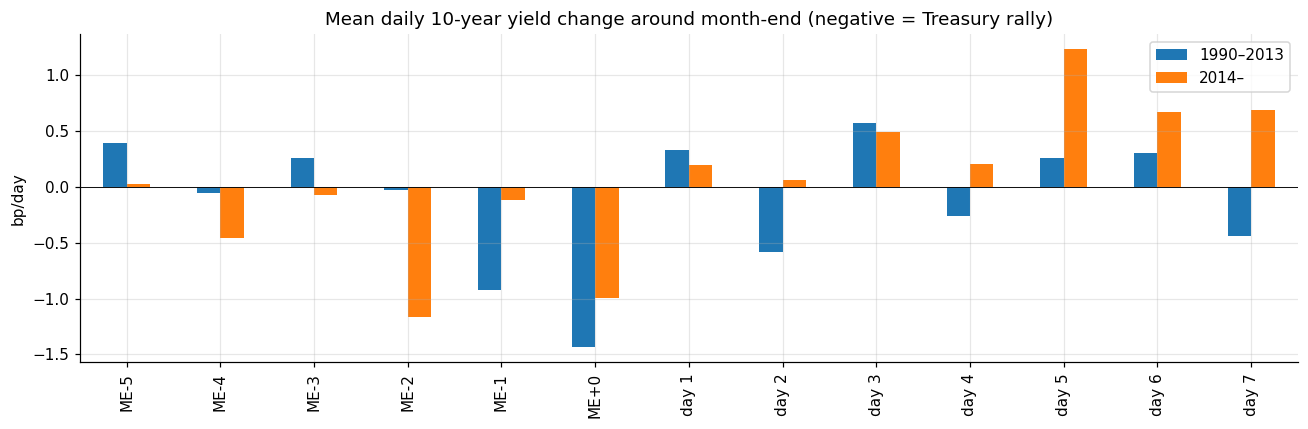

1990–2013: last 3 days -0.794 bp/day vs other days +0.018 (t -3.78)
2014–: last 3 days -0.760 bp/day vs other days +0.208 (t -4.01)


In [2]:
rel = pd.Series(np.where(k_end <= 5, -k_end, dom + 100), index=cal)
labels = [-5, -4, -3, -2, -1, 0, 101, 102, 103, 104, 105, 106, 107]
tab = pd.DataFrame({nm: dy.DGS10[m].groupby(rel[m]).mean() for nm, m in [("1990–2013", cal < SPLIT), ("2014–", cal >= SPLIT)]}).loc[labels]
tab.index = [f"ME{k:+d}" if k <= 0 else f"day {k - 100}" for k in labels]
print(tab.round(2).T.to_string())
tab.plot.bar(figsize=(12, 4)); plt.axhline(0, c="k", lw=0.6); plt.ylabel("bp/day")
plt.title("Mean daily 10-year yield change around month-end (negative = Treasury rally)"); plt.tight_layout(); plt.show()
for nm, m in [("1990–2013", cal < SPLIT), ("2014–", cal >= SPLIT)]:
    a = dy.DGS10[m & (k_end <= 2).values].dropna(); b = dy.DGS10[m & (k_end > 2).values].dropna(); t, _ = stats.ttest_ind(a, b, equal_var=False)
    print(f"{nm}: last 3 days {a.mean():+.3f} bp/day vs other days {b.mean():+.3f} (t {t:+.2f})")

## 3. Last three days, by tenor and by year
**What this does.** Sum of the daily yield changes over the last 3 trading days of each month (one observation per
month), by tenor, era and year. t-stats across months.

      era  months           DGS2           DGS5          DGS10          DGS30
1990–2013     300 -3.16 (t -5.5) -3.00 (t -4.8) -2.38 (t -4.0) -2.55 (t -4.8)
    2014–     153 -1.54 (t -2.6) -2.68 (t -4.1) -2.25 (t -3.6) -1.71 (t -3.0)
    2020–      81 -0.84 (t -0.9) -2.33 (t -2.3) -1.81 (t -1.9) -1.01 (t -1.2)


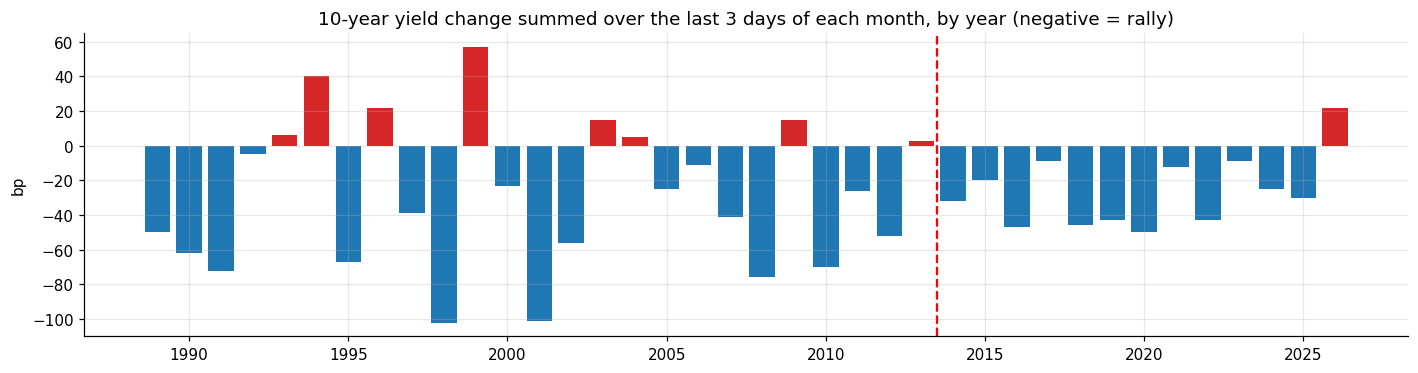

years with a month-end rally: 29 of 38; since 2014: 12 of 13


In [3]:
rows = []
for per in ym.unique():
    days = cal[ym == per]
    if len(days) < 10: continue
    i = cal.get_loc(days[-1])
    rows.append({"m": per, "y": per.year, **{c: dy[c].iloc[i - 2:i + 1].sum() for c in ["DGS2", "DGS5", "DGS10", "DGS30"]}})
M = pd.DataFrame(rows)
out = []
for nm, m in [("1990–2013", M.y < 2014), ("2014–", M.y >= 2014), ("2020–", M.y >= 2020)]:
    d = M[m]
    out.append({"era": nm, "months": len(d), **{c: f"{d[c].mean():+.2f} (t {d[c].mean() / d[c].sem():+.1f})" for c in ["DGS2", "DGS5", "DGS10", "DGS30"]}})
print(pd.DataFrame(out).to_string(index=False))
yr = M.groupby("y").DGS10.sum()
fig, ax = plt.subplots(figsize=(13, 3.5)); ax.bar(yr.index, yr.values, color=np.where(yr < 0, "C0", "C3")); ax.axvline(2013.5, c="r", ls="--")
ax.set_title("10-year yield change summed over the last 3 days of each month, by year (negative = rally)"); ax.set_ylabel("bp"); plt.tight_layout(); plt.show()
print(f"years with a month-end rally: {(yr < 0).sum()} of {len(yr)}; since 2014: {(yr.loc[2014:] < 0).sum()} of {len(yr.loc[2014:])}")

**Interpretation.**
- **The rally is in both eras at almost the same size.** The 10-year yield falls 2.3bp over the last 3 days in
  1990–2013 (t ≈ −3.6) and 2.25bp in 2014– (t ≈ −3.6), while other days drift up in 2014– (rising-rate decade).
- **All tenors.** 2y to 30y all rally (t −2.6 to −5.5). Since 2020 the belly (5y: −2.3bp, t −2.3) is the most
  reliable, and 2y / 30y are weaker.
- **Persistent.** Month-end windows summed per year are negative in most years, including 12 of 13 since 2014
  (2026 to date is the exception).

## 4. Is it the extension? Size of the index extension vs the rally
**What this does.** An extension proxy: duration-weighted coupon issuance settling in the month (offering ×
approximate duration, $bn-years), relative to its trailing 12-month average (known by month-end). If month-end demand
is index extension, bigger extensions should bring bigger rallies.

In [4]:
au = pd.read_csv(SRC / "auctions.csv", parse_dates=["auction_date", "issue_date"])
yrs = au.term.str.extract(r"^(\d+)-Year")[0].astype(float)
DUR = {2: 1.9, 3: 2.8, 5: 4.6, 7: 6.3, 10: 8.5, 20: 14, 30: 18}
au["dur"] = yrs.map(lambda v: DUR[min(DUR, key=lambda k: abs(k - v))] if v == v else np.nan)
ext = (au.offering * au.dur / 1e9).groupby(au.issue_date.dt.to_period("M")).sum()
M["ext"] = M.m.map(ext); M["ext_rel"] = M.ext / M.ext.rolling(12, min_periods=6).mean().shift(1)
for nm, m in [("1990–2013", M.y < 2014), ("2014–", M.y >= 2014)]:
    d = M[m].dropna(subset=["ext_rel"])
    f = sm.OLS(d.DGS10, sm.add_constant(d.ext_rel)).fit(cov_type="HC1")
    d["t3"] = pd.qcut(d.ext_rel.rank(method="first"), 3, labels=["small", "normal", "big"])
    print(f"{nm}: slope on relative extension {f.params.ext_rel:+.2f} (t {f.tvalues.ext_rel:+.2f}); by tercile:",
          d.groupby("t3", observed=True).DGS10.mean().round(2).to_dict())

1990–2013: slope on relative extension +0.40 (t +0.38); by tercile: {'small': -2.42, 'normal': -2.24, 'big': -2.31}
2014–: slope on relative extension -0.51 (t -0.36); by tercile: {'small': -3.2, 'normal': -0.76, 'big': -2.78}


**Interpretation.**
- **No dose-response to this proxy** (|t| < 0.5). Month-end demand does not scale with how much new coupon supply
  settled that month. Either the proxy is too crude (it ignores bills, maturities leaving the index, coupon cash
  and corporate/MBS index moves), or the bid is generic month-end benchmark demand (index funds, liability-driven
  investors, window dressing) rather than the extension itself. The rally is robust; the precise mechanism is not pinned
  down by this test.

## 5. Confounders and placebo windows
**What this does.** Month-end windows sometimes contain an FOMC announcement (late Jan/Apr/Jul/Oct), and quarter-ends
have their own balance-sheet effects. Split by both. Then run the same 3-day long in other windows of the month
(trading days 1–3, 5–7, 10–12, 14–16).
Trade return = IEF minus SHY (duration beyond cash), total return.

In [5]:
fomc = set(pd.read_csv("../FOMC Pitch/data/fomc.csv", parse_dates=["date"]).date)
inpos = (kE <= 2).values
def monthly(mask, cost=2.0):
    pn = pd.Series(np.where(mask, er["IEF"] - er["SHY"], 0), index=ec) - cost * pd.Series(mask.astype(int), index=ec).diff().clip(lower=0).fillna(0)
    return pn.groupby(ymE).sum()
mon = monthly(inpos)
has_fomc = pd.Series({p: any(d in fomc for d in ec[(ymE == p) & inpos]) for p in mon.index})
qend = pd.Series({p: p.month in (3, 6, 9, 12) for p in mon.index})
rows = []
for nm, mk in [("all", np.ones(len(mon), bool)), ("no FOMC in window", ~has_fomc.values), ("FOMC in window", has_fomc.values),
               ("quarter-ends", qend.values), ("other months", ~qend.values)]:
    for per, m in [("2002–13", mon.index.year < 2014), ("2014–", mon.index.year >= 2014)]:
        x = mon[mk & m]; rows.append({"subset": nm, "era": per, "bp/month (net 2bp)": x.mean(), "t": x.mean() / x.std() * np.sqrt(len(x)), "months": len(x)})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nplacebo 3-day windows, IEF − SHY gross, 2014–:")
for a in [1, 5, 10, 14]:
    x = monthly(((domE >= a) & (domE < a + 3)).values, 0); x = x[x.index.year >= 2014]
    print(f"  trading days {a}–{a + 2}: {x.mean():+.1f} bp/month (t {x.mean() / x.std() * np.sqrt(len(x)):+.2f})")

           subset     era  bp/month (net 2bp)     t  months
              all 2002–13               12.64  2.51     144
              all   2014–               13.09  3.16     154
no FOMC in window 2002–13               18.06  3.31     122
no FOMC in window   2014–               11.80  2.67     123
   FOMC in window 2002–13              -17.42 -1.52      22
   FOMC in window   2014–               18.21  1.68      31
     quarter-ends 2002–13               10.40  1.21      48
     quarter-ends   2014–               13.34  1.82      51
     other months 2002–13               13.76  2.21      96
     other months   2014–               12.96  2.57     103

placebo 3-day windows, IEF − SHY gross, 2014–:
  trading days 1–3: -2.4 bp/month (t -0.43)
  trading days 5–7: -14.3 bp/month (t -3.59)
  trading days 10–12: -1.1 bp/month (t -0.27)
  trading days 14–16: +5.6 bp/month (t +1.32)


**Interpretation.**
- **Not FOMC.** Months without an FOMC announcement in the window carry the effect on their own (+18bp/month,
  t 3.3 in 2002–13; +12bp, t 2.7 in 2014–). Months with one are noisier and of mixed sign.
- **Not just quarter-ends.** Ordinary month-ends are as strong as quarter-ends (2014–: +13bp, t 2.6 vs +13bp, t 1.8).
- **Placebo windows are flat (days 1–3, 10–12, 14–16), except days 5–7, which sell off (t −3.6).** That fits a
  monthly cycle: duration is bought into month-end and partly given back early in the next month (and payrolls
  usually land in days 1–7). Shorting days 5–7 was not part of the hypothesis, so it is not used.

## 6. Tradable version
**Rule.** At the close of the 4th-to-last trading day of each month, buy IEF and sell an equal dollar amount of SHY
(or the futures equivalent: long 10-year note futures, about 8.5 years of duration). Sell at the close of the last
trading day. Three days a month in the market. Cost 2bp per round trip for the ETF pair (futures are cheaper). The
same with TLT for longer duration. Also the futures-equivalent P&L from the 10-year yield (−8.5 × Δy, 0.25bp of yield
round-trip cost ≈ 2bp of price).

                      leg  cost bp       era  bp/month  ann. Sharpe    t  hit  worst month
                  IEF−SHY        0   2002–13     14.54         0.83 2.89 0.58      -182.04
                  IEF−SHY        0     2014–     15.09         1.02 3.64 0.62       -92.13
                  IEF−SHY        0     2020–     13.51         0.81 2.13 0.56       -92.13
                  IEF−SHY        2   2002–13     12.64         0.72 2.51 0.57      -184.04
                  IEF−SHY        2     2014–     13.09         0.88 3.16 0.60       -94.13
                  IEF−SHY        2     2020–     11.51         0.69 1.81 0.55       -94.13
                  IEF−SHY        5   2002–13      9.78         0.56 1.94 0.56      -187.04
                  IEF−SHY        5     2014–     10.09         0.68 2.44 0.59       -97.13
                  IEF−SHY        5     2020–      8.51         0.51 1.34 0.54       -97.13
                  TLT−SHY        0   2002–13     31.83         0.84 2.91 0.59      -494.97

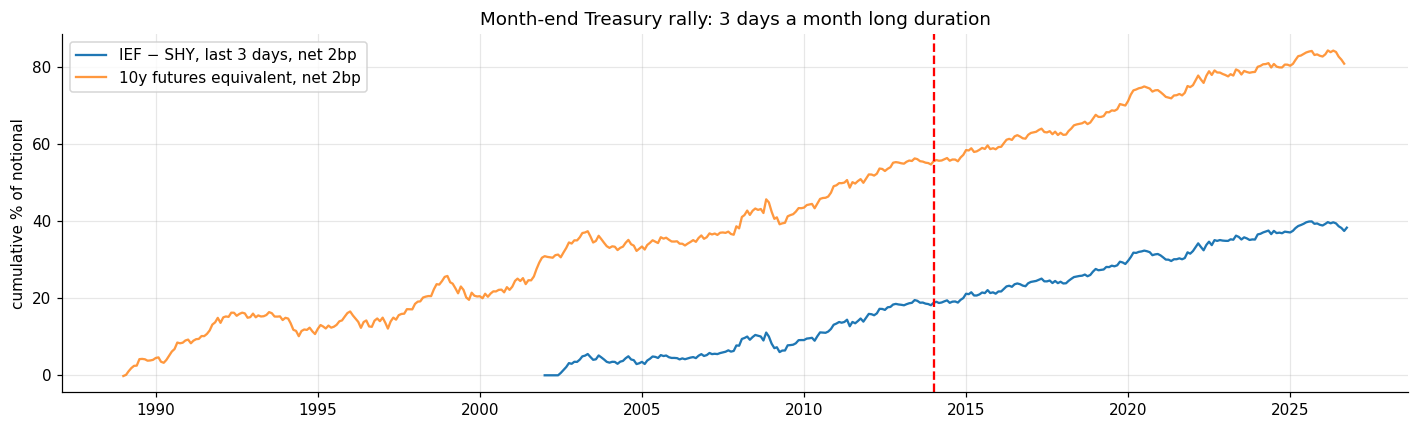

IEF−SHY net by year (bp): {2002: 351, 2003: -1, 2004: -37, 2005: 138, 2006: 52, 2007: 272, 2008: 232, 2009: -92, 2010: 397, 2011: 182, 2012: 346, 2013: -20, 2014: 187, 2015: 113, 2016: 271, 2017: 39, 2018: 262, 2019: 199, 2020: 259, 2021: 9, 2022: 340, 2023: 27, 2024: 194, 2025: 190, 2026: -75}


In [6]:
rows = []
for tk in ["IEF", "TLT"]:
    for c in [0, 2, 5]:
        mon_t = (pd.Series(np.where(inpos, er[tk] - er["SHY"], 0), index=ec) - c * pd.Series(inpos.astype(int), index=ec).diff().clip(lower=0).fillna(0)).groupby(ymE).sum()
        for per, m in [("2002–13", mon_t.index.year < 2014), ("2014–", mon_t.index.year >= 2014), ("2020–", mon_t.index.year >= 2020)]:
            x = mon_t[m]
            rows.append({"leg": f"{tk}−SHY", "cost bp": c, "era": per, "bp/month": x.mean(), "ann. Sharpe": x.mean() / x.std() * np.sqrt(12),
                         "t": x.mean() / x.std() * np.sqrt(len(x)), "hit": (x > 0).mean(), "worst month": x.min()})
fut = (-8.5 * M.set_index("m").DGS10 - 2.0)
for per, m in [("1990–2013", fut.index.year < 2014), ("2014–", fut.index.year >= 2014), ("2020–", fut.index.year >= 2020)]:
    x = fut[m]; rows.append({"leg": "10y futures (from yields)", "cost bp": 2, "era": per, "bp/month": x.mean(), "ann. Sharpe": x.mean() / x.std() * np.sqrt(12),
                             "t": x.mean() / x.std() * np.sqrt(len(x)), "hit": (x > 0).mean(), "worst month": x.min()})
R6 = pd.DataFrame(rows); print(R6.round(2).to_string(index=False))
mon2 = monthly(inpos, 2)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(mon2.index.to_timestamp(), mon2.cumsum() / 100, label="IEF − SHY, last 3 days, net 2bp")
ax.plot(fut.index.to_timestamp(), fut.cumsum() / 100, label="10y futures equivalent, net 2bp", alpha=0.8)
ax.axvline(SPLIT, c="r", ls="--"); ax.set_ylabel("cumulative % of notional"); ax.legend()
ax.set_title("Month-end Treasury rally: 3 days a month long duration"); plt.tight_layout(); plt.show()
print("IEF−SHY net by year (bp):", mon2.groupby(mon2.index.year).sum().round(0).astype(int).to_dict())

**Interpretation.**
- **Tradable at small cost.** IEF − SHY over the last 3 days, net of 2bp: about +13bp a month in both 2002–13 (Sharpe
  0.72, t 2.5) and 2014– (Sharpe 0.88, t 3.2). The futures equivalent built from yields since 1990 shows the same.
  Hit rate about 60%.
- **Weaker since 2020** (Sharpe ≈ 0.7, t ≈ 1.8 for IEF; TLT about half that). Long duration fades: the effect has moved
  to the belly of the curve (§3: 5y strongest since 2020).
- **Capital efficient.** The Sharpe is on monthly P&L, but the money is used 3 days in 21. It works as an overlay
  for anyone who holds or benchmarks duration (buy into month-end, not after), or as a small futures sleeve.

## 7. Takeaways

| question | answer |
|---|---|
| Do Treasuries rally into month-end? | **Yes.** 10y yield −2.3bp over the last 3 days, t ≈ −3.6, in both 1990–2013 and 2014–2026; all tenors. |
| Stable? | Same size in both eras; month-end windows net negative in 12 of 13 years since 2014. Weaker since 2020 at the long end, 5y still strong. |
| Mechanism | Month-end benchmark demand. The issuance-based extension proxy does not scale with it, so it is not pinned to new supply specifically. |
| Confounders | Not FOMC, not quarter-ends. Placebo windows flat except an early-month give-back (days 5–7). |
| Tradable | **Yes, modestly.** IEF−SHY (or 10y futures) for 3 days a month: net Sharpe 0.72 (2002–13) / 0.88 (2014–), t 2.5 / 3.2; 2020–: 0.69 (t 1.8). |

**Verdict: promising and tradable.** It has a calendar-fixed, mechanical, non-informational bid (bond index month-end
rebalancing), the same size in two independent halves of a 36-year sample, no look-ahead, survives FOMC and
quarter-end splits, has clean placebo windows, and uses the cheapest instrument there is. Caveats: known to
practitioners (the "month-end extension trade"); weaker since 2020 at the long end; the extension proxy does not
explain cross-month variation.

**Next steps.** Futures with actual settlement prices and roll (ZF/ZN/TN) instead of yields; a curve-neutral version
(belly vs wings) since 2020; a better extension measure (index duration change, which Bloomberg publishes); test the
same in Bunds/Gilts (same month-end index mechanics, independent sample).